# Tugas Machine Learning – Deteksi Penipuan Kartu Kredit
**Dataset:** `creditcard.csv` (284.807 transaksi, 31 kolom)
**Tujuan:** klasifikasi biner, memprediksi apakah transaksi `Class = 1` (fraud) atau `Class = 0` (normal).

**Tentang dataset:**
- `V1`–`V28` adalah hasil PCA (sudah dianonimkan dan sudah ter-scale).
- `Time` = detik sejak transaksi pertama (rentang ±2 hari), `Amount` = nominal transaksi.
- Data **sangat tidak seimbang**: fraud hanya ±0,17%. Karena itu **accuracy tidak boleh dijadikan patokan** (model yang menebak "normal" terus sudah akurat 99,8%). Metrik utama: **Precision, Recall, F1, dan PR-AUC**.

## 1. Loading

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("creditcard.csv")
print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Cleaning & Transformation

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [4]:
# Cek missing value
missing_values = df.isnull().sum()
print("Total missing value:", missing_values.sum())
missing_values[missing_values > 0]

Total missing value: 0


Series([], dtype: int64)

Tidak ada missing value, jadi tidak perlu imputasi. Selanjutnya cek duplikat.

In [5]:
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape setelah drop duplikat:", df.shape)
print(df['Class'].value_counts())

Jumlah baris duplikat: 1081


Shape setelah drop duplikat: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


### Outlier
Pada dataset fraud, outlier **tidak dihapus**: transaksi fraud justru sering muncul sebagai nilai ekstrem. Kalau outlier dibuang, banyak sampel fraud ikut hilang. Outlier hanya dicek untuk informasi.

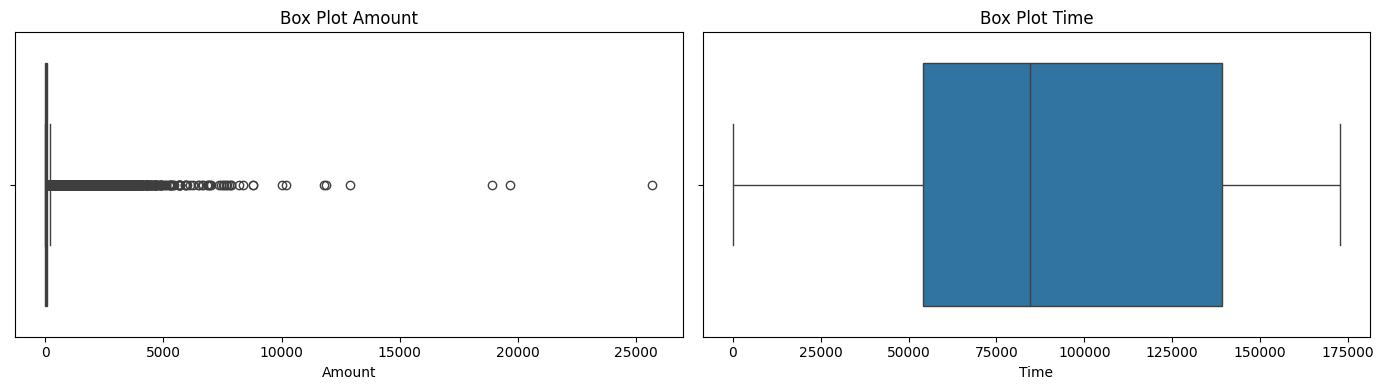

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df['Amount'], ax=axes[0]); axes[0].set_title('Box Plot Amount')
sns.boxplot(x=df['Time'], ax=axes[1]);   axes[1].set_title('Box Plot Time')
plt.tight_layout(); plt.show()

In [7]:
# Hitung jumlah outlier Amount (IQR) - hanya sebagai informasi
Q1, Q3 = df['Amount'].quantile([0.25, 0.75])
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
n_out = (df['Amount'] > batas_atas).sum()
print(f"Batas atas IQR Amount: {batas_atas:.2f}")
print(f"Jumlah outlier: {n_out} ({n_out/len(df):.1%} data) -> TIDAK dihapus")
print("Outlier yang fraud:", ((df['Amount'] > batas_atas) & (df['Class'] == 1)).sum())

Batas atas IQR Amount: 185.38
Jumlah outlier: 31685 (11.2% data) -> TIDAK dihapus
Outlier yang fraud: 87


### Transformasi fitur
- `Time` berupa detik sejak awal data, maknanya kurang berguna kalau mentah. Diubah menjadi **`hour_of_day`** (jam dalam sehari, 0–23) supaya bisa menangkap pola jam transaksi.
- `Amount` sangat condong ke kanan, jadi nanti di-scale. Scaling dilakukan **setelah splitting** (bagian 4) supaya tidak ada kebocoran data.
- `V1`–`V28` sudah hasil PCA, tidak perlu diproses lagi. Tidak ada kolom kategorikal, jadi **tidak perlu encoding**.

In [8]:
df['hour_of_day'] = ((df['Time'] // 3600) % 24).astype(int)
df = df.drop(columns='Time')

X = df.drop(columns='Class')
y = df['Class']

print("Shape X:", X.shape)
print("Fitur  :", X.columns.tolist())

Shape X: (283726, 30)
Fitur  : ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'hour_of_day']


## 3. EDA (Exploratory Data Analysis)

Class
0    283253
1       473
Name: count, dtype: int64

Persentase fraud: 0.1667%


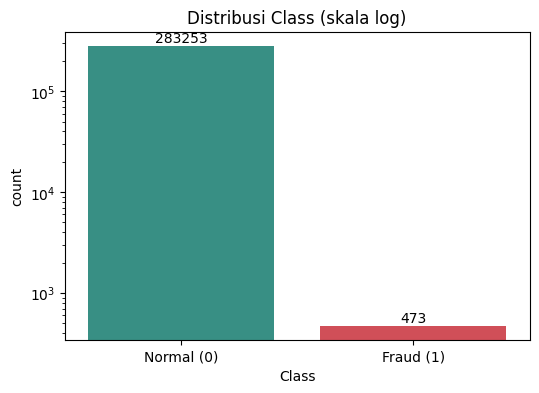

In [9]:
# Distribusi kelas
counts = y.value_counts()
print(counts)
print(f"\nPersentase fraud: {y.mean():.4%}")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette=['#2a9d8f', '#e63946'])
ax.set_yscale('log')
ax.set_xticklabels(['Normal (0)', 'Fraud (1)'])
ax.set_title('Distribusi Class (skala log)')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.show()

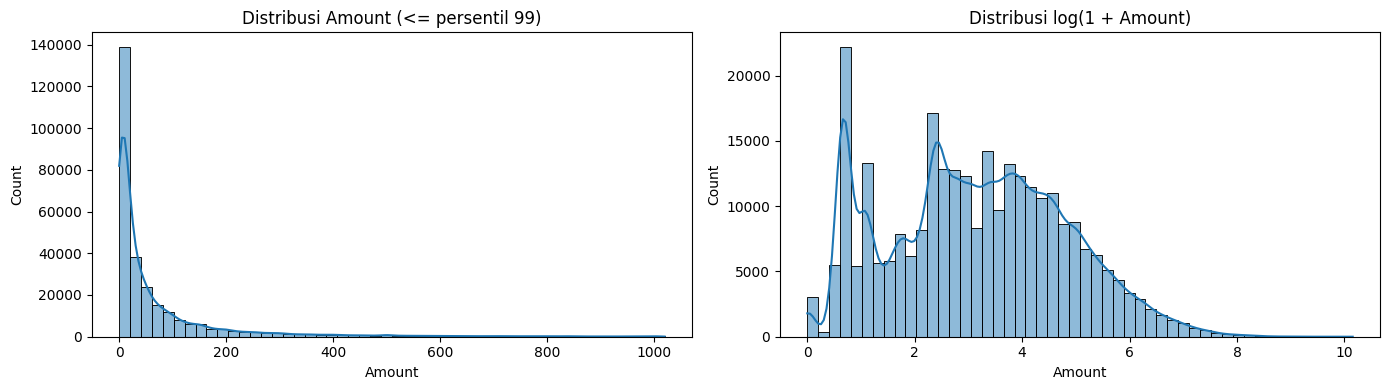

In [10]:
# Distribusi Amount (dipotong sampai persentil 99 supaya bentuknya terlihat)
batas = df['Amount'].quantile(0.99)
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
sns.histplot(df[df['Amount'] <= batas]['Amount'], bins=50, kde=True)
plt.title('Distribusi Amount (<= persentil 99)')
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['Amount']), bins=50, kde=True)
plt.title('Distribusi log(1 + Amount)')
plt.tight_layout(); plt.show()

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


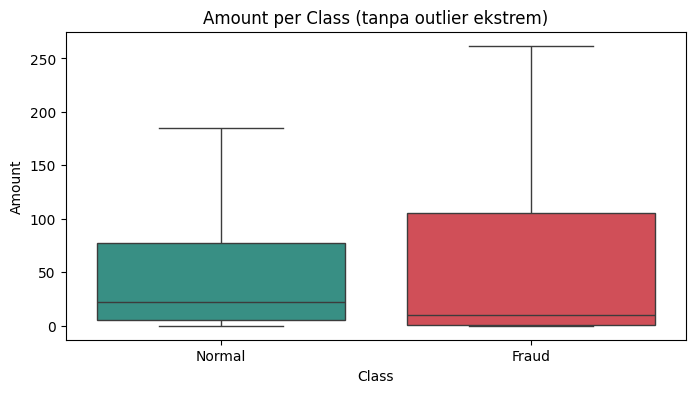

In [11]:
# Amount: Normal vs Fraud
print(df.groupby('Class')['Amount'].describe().round(2))

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Class', y='Amount', showfliers=False, palette=['#2a9d8f', '#e63946'])
plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.title('Amount per Class (tanpa outlier ekstrem)')
plt.show()

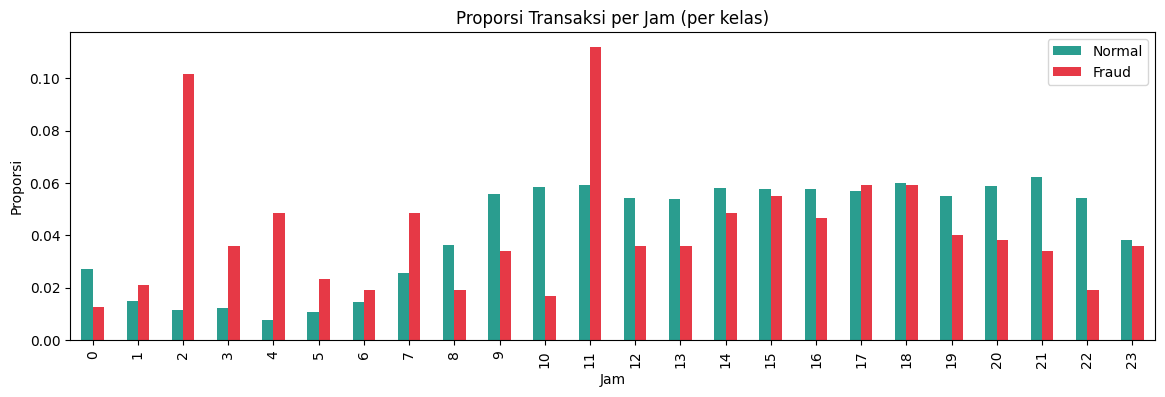

In [12]:
# Jam transaksi: normal vs fraud (dinormalisasi per kelas supaya bisa dibandingkan)
jam = pd.crosstab(df['hour_of_day'], df['Class'], normalize='columns')
jam.columns = ['Normal', 'Fraud']
jam.plot(kind='bar', figsize=(14, 4), color=['#2a9d8f', '#e63946'])
plt.title('Proporsi Transaksi per Jam (per kelas)')
plt.ylabel('Proporsi'); plt.xlabel('Jam')
plt.show()

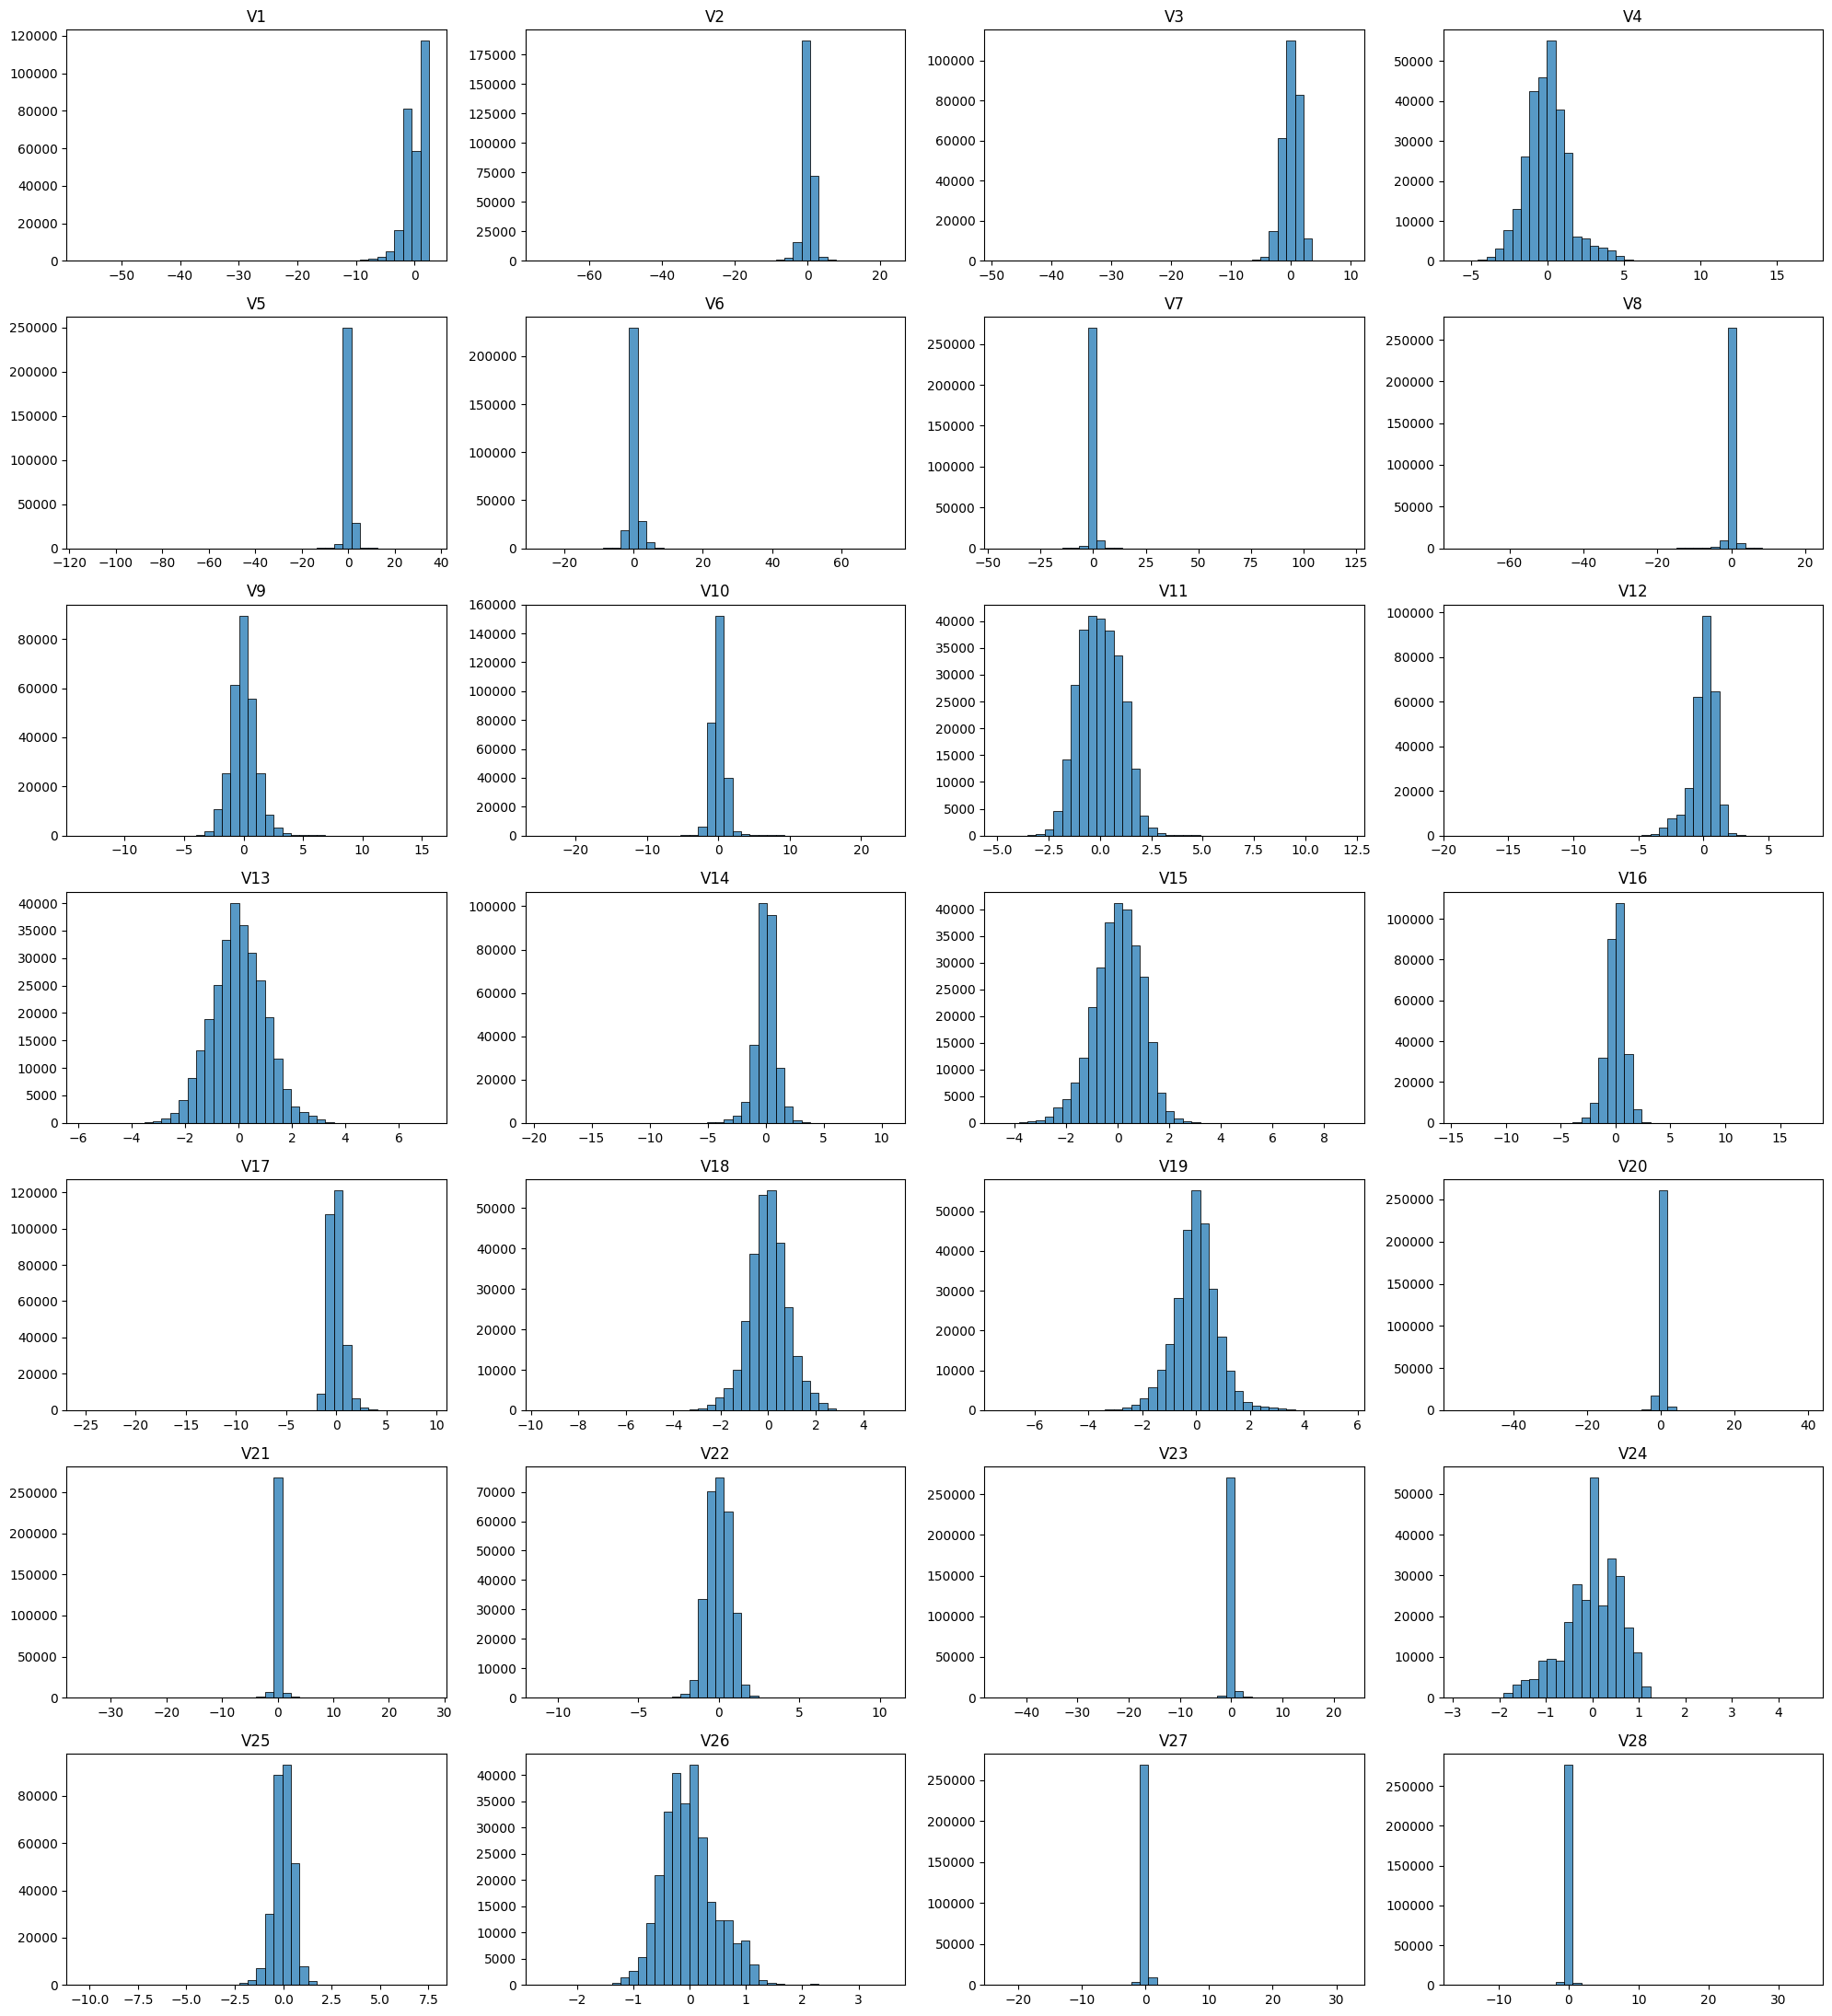

In [13]:
# Distribusi semua fitur V1-V28
v_cols = [c for c in df.columns if c.startswith('V')]
fig, axes = plt.subplots(7, 4, figsize=(20, 22))
for ax, c in zip(axes.flatten(), v_cols):
    sns.histplot(df[c], bins=40, ax=ax)
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

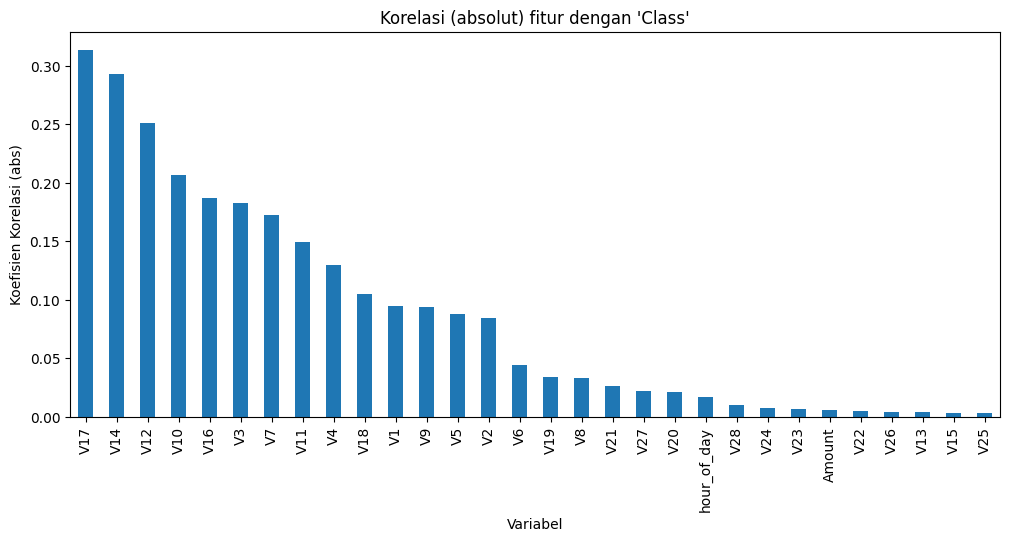

10 fitur paling berkorelasi dengan Class:
V17   -0.313
V14   -0.293
V12   -0.251
V10   -0.207
V16   -0.187
V3    -0.182
V7    -0.172
V11    0.149
V4     0.129
V18   -0.105
Name: Class, dtype: float64


In [14]:
# Korelasi semua fitur terhadap target 'Class'
target_corr = df.corr()['Class'].drop('Class')
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
target_corr_sorted.plot(kind='bar')
plt.title("Korelasi (absolut) fitur dengan 'Class'")
plt.xlabel('Variabel'); plt.ylabel('Koefisien Korelasi (abs)')
plt.show()

print("10 fitur paling berkorelasi dengan Class:")
print(target_corr[target_corr_sorted.head(10).index].round(3))

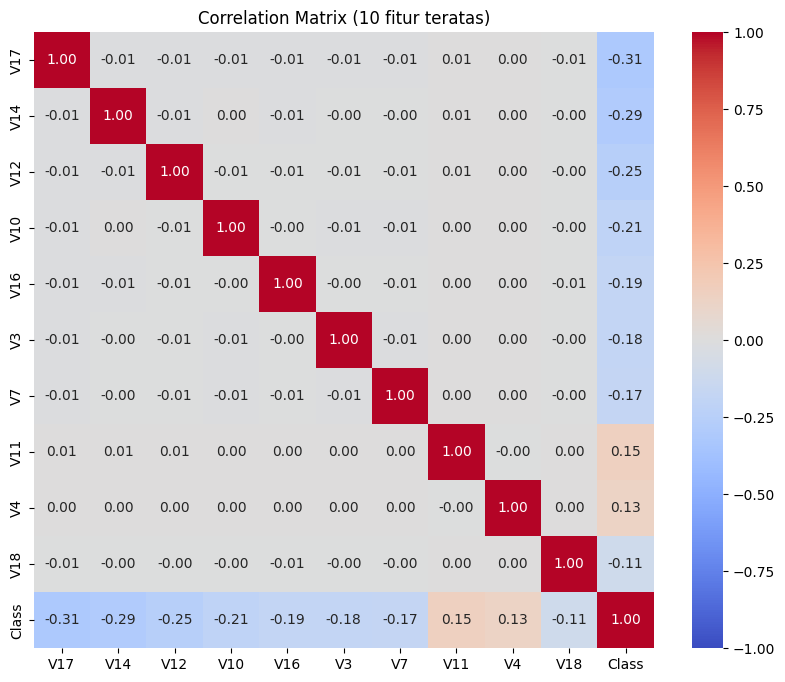

In [15]:
# Heatmap korelasi untuk 10 fitur teratas + Class
top10 = target_corr_sorted.head(10).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(df[top10 + ['Class']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix (10 fitur teratas)')
plt.show()

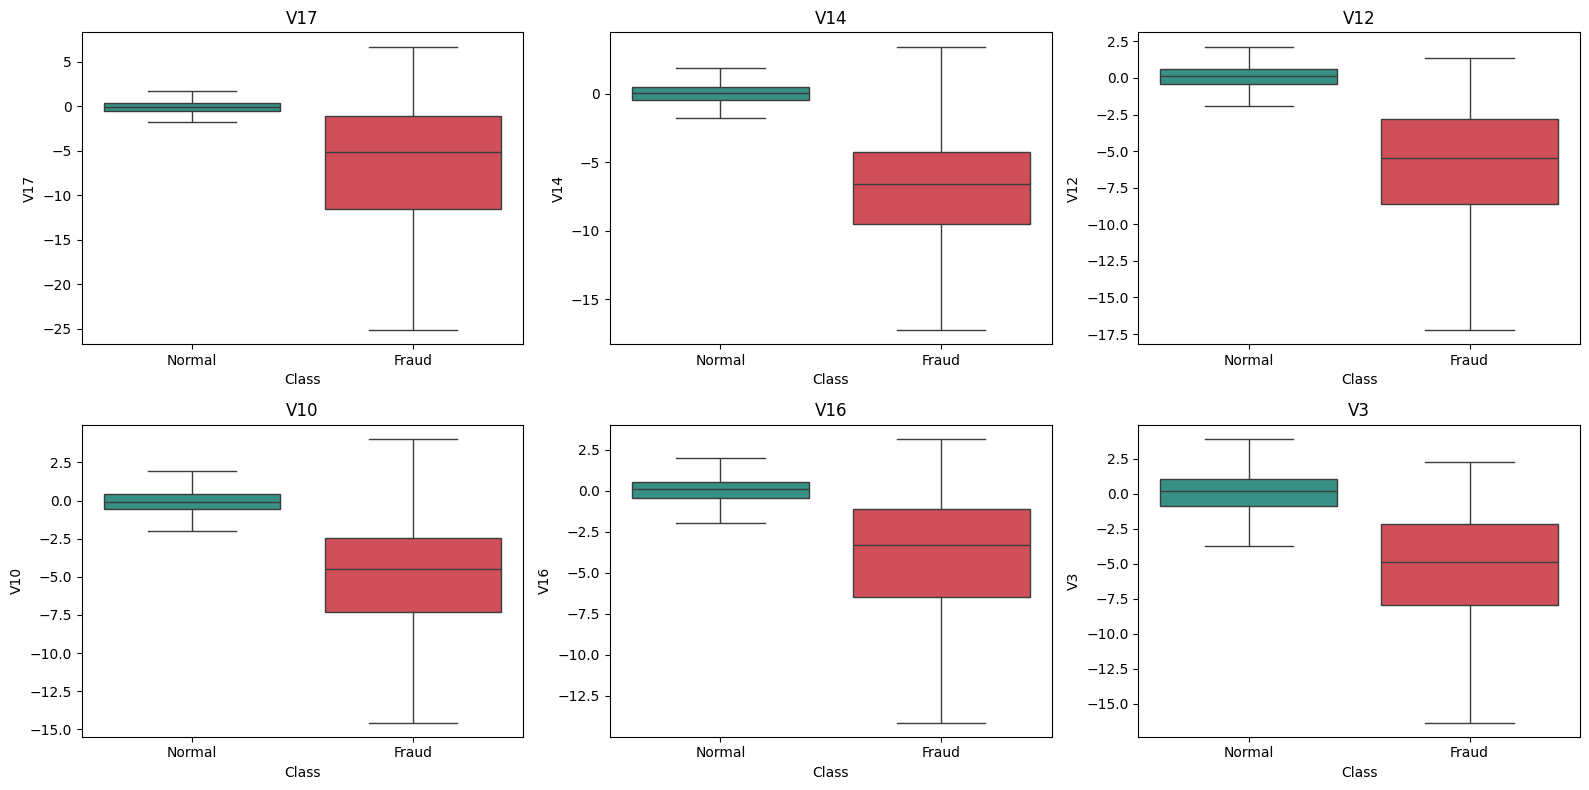

In [16]:
# Box plot 6 fitur teratas: Normal vs Fraud
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flatten(), top10[:6]):
    sns.boxplot(data=df, x='Class', y=c, showfliers=False, ax=ax, palette=['#2a9d8f', '#e63946'])
    ax.set_xticklabels(['Normal', 'Fraud']); ax.set_title(c)
plt.tight_layout(); plt.show()

## 3b. ExDA (Explanatory Data Analysis)
Ringkasan temuan EDA untuk disampaikan ke pembaca: satu grafik, satu pesan.

In [17]:
fraud = df[df['Class'] == 1]
normal = df[df['Class'] == 0]

print("TEMUAN UTAMA")
print("-" * 60)
print(f"1. Fraud sangat langka: {len(fraud)} dari {len(df)} transaksi ({y.mean():.3%}).")
print(f"2. Rata-rata nominal: normal {normal['Amount'].mean():.2f} vs fraud {fraud['Amount'].mean():.2f}")
print(f"   Median nominal   : normal {normal['Amount'].median():.2f} vs fraud {fraud['Amount'].median():.2f}")
print(f"3. Fitur paling membedakan fraud: {', '.join(top10[:5])}")

TEMUAN UTAMA
------------------------------------------------------------
1. Fraud sangat langka: 473 dari 283726 transaksi (0.167%).
2. Rata-rata nominal: normal 88.41 vs fraud 123.87
   Median nominal   : normal 22.00 vs fraud 9.82
3. Fitur paling membedakan fraud: V17, V14, V12, V10, V16


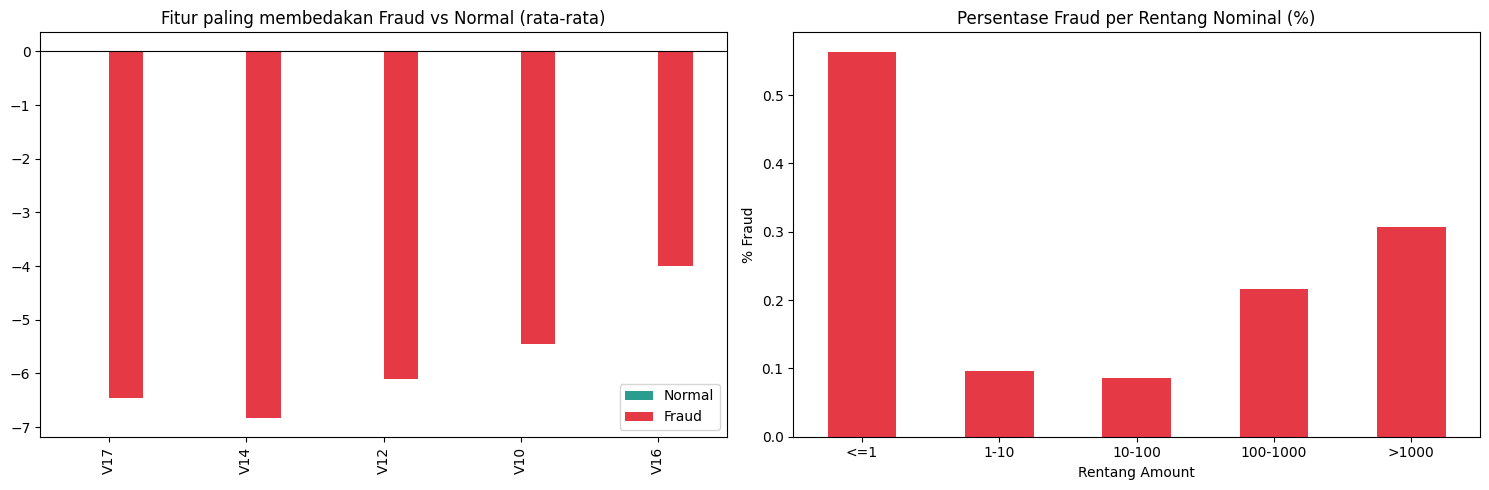

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafik 1: fitur paling membedakan (rata-rata per kelas)
beda = df.groupby('Class')[top10[:5]].mean().T
beda.columns = ['Normal', 'Fraud']
beda.plot(kind='bar', ax=axes[0], color=['#2a9d8f', '#e63946'])
axes[0].set_title('Fitur paling membedakan Fraud vs Normal (rata-rata)')
axes[0].axhline(0, color='black', linewidth=0.8)

# Grafik 2: persentase fraud per rentang Amount
df['amount_bin'] = pd.cut(df['Amount'], bins=[-0.01, 1, 10, 100, 1000, df['Amount'].max()],
                          labels=['<=1', '1-10', '10-100', '100-1000', '>1000'])
rate = df.groupby('amount_bin', observed=True)['Class'].mean() * 100
rate.plot(kind='bar', ax=axes[1], color='#e63946')
axes[1].set_title('Persentase Fraud per Rentang Nominal (%)')
axes[1].set_ylabel('% Fraud'); axes[1].set_xlabel('Rentang Amount')
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
df = df.drop(columns='amount_bin')

**Kesimpulan ExDA:** fraud sangat jarang dan dicirikan oleh pola nilai tertentu pada beberapa komponen PCA (misalnya `V14`, `V17`, `V12`, `V10`), bukan oleh nominal transaksi saja. Karena itu dibutuhkan model yang bisa menangkap kombinasi fitur dan metrik yang fokus ke kelas fraud (Precision/Recall/PR-AUC), bukan accuracy.

## 4. Splitting
Split dilakukan **sebelum** scaling. `stratify=y` wajib di sini supaya proporsi fraud (±0,17%) sama di data latih dan data uji. Tanpa stratify, data uji bisa kebetulan hanya berisi sedikit fraud.

In [19]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

In [20]:
print("Jumlah data       :", len(X))
print("Jumlah data latih :", len(x_train))
print("Jumlah data test  :", len(x_test))
print()
print("Jumlah fraud di train:", y_train.sum(), f"({y_train.mean():.4%})")
print("Jumlah fraud di test :", y_test.sum(),  f"({y_test.mean():.4%})")

Jumlah data       : 283726
Jumlah data latih : 226980
Jumlah data test  : 56746

Jumlah fraud di train: 378 (0.1665%)
Jumlah fraud di test : 95 (0.1674%)


In [21]:
# Standardisasi hanya untuk Amount dan hour_of_day (V1-V28 sudah hasil PCA).
# Scaler di-fit HANYA pada data latih, lalu diterapkan ke data test.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

prep = ColumnTransformer(
    [('scale', StandardScaler(), ['Amount', 'hour_of_day'])],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

x_train_s = prep.fit_transform(x_train)
x_test_s  = prep.transform(x_test)
x_train_s.head()

,Amount,hour_of_day,V1,V2,V3,V4,V5,V6,V7,V8,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
223104,0.020870,0.165698,1.709589,-0.485363,-0.316887,1.566062,-0.509213,0.009511,-0.251914,0.123666,...,0.371914,-0.134719,-0.412191,-1.124579,0.370342,-0.069985,-0.416379,-1.133093,0.036162,-0.025622
59886,-0.199380,-0.176603,1.135719,0.236747,0.239032,1.092761,-0.082971,-0.476239,0.212080,-0.125596,...,-0.742743,-0.081628,0.080210,0.254963,-0.104037,0.098866,0.615376,-0.303651,0.026332,0.023712
91065,-0.348012,0.508000,-0.761176,0.698266,0.943093,-1.385104,-0.389418,-0.224904,-0.181915,0.825254,...,-0.694136,-0.271289,-0.036347,-0.296605,0.027257,-0.332700,-0.370728,0.765898,0.048758,-0.017145
126476,0.322298,1.192604,-1.113383,-2.238382,0.692251,-1.548396,1.247487,0.196084,-0.570404,-0.010892,...,1.704277,0.738661,-0.392935,-1.316643,0.623143,-1.790266,-0.470346,-0.486033,-0.093357,-0.060130
130649,-0.347616,1.363755,1.188679,-0.485522,0.990296,-0.780954,-1.364299,-0.646853,-0.757089,0.172751,...,0.777371,-0.202380,0.038180,0.260555,-0.007762,0.524924,0.400090,-0.712413,0.081820,0.024462


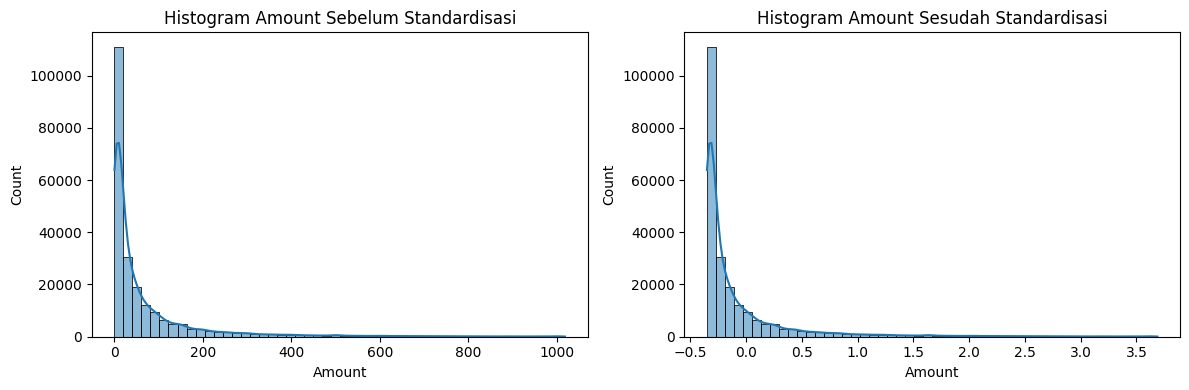

In [22]:
# Histogram Amount sebelum vs sesudah standardisasi
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(x_train['Amount'][x_train['Amount'] <= batas], bins=50, kde=True)
plt.title('Histogram Amount Sebelum Standardisasi')
plt.subplot(1, 2, 2)
sns.histplot(x_train_s['Amount'][x_train['Amount'] <= batas], bins=50, kde=True)
plt.title('Histogram Amount Sesudah Standardisasi')
plt.tight_layout(); plt.show()

## 5. Modeling
Karena kelasnya timpang, model diberi **`class_weight='balanced'`** (kesalahan pada fraud dihukum lebih berat). Untuk Gradient Boosting dipakai `HistGradientBoostingClassifier`, versi cepat dari Gradient Boosting yang jauh lebih efisien untuk data ratusan ribu baris.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Model 1: Logistic Regression
LogR = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=184)
LogR.fit(x_train_s, y_train)

# Model 2: Decision Tree
DT = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=184)
DT.fit(x_train_s, y_train)

# Model 3: Random Forest
RF = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=5,
                            class_weight='balanced_subsample', n_jobs=-1, random_state=184)
RF.fit(x_train_s, y_train)

# Model 4: Gradient Boosting (versi cepat)
GBC = HistGradientBoostingClassifier(class_weight='balanced', random_state=184)
GBC.fit(x_train_s, y_train)

print("Semua model selesai dilatih")

Semua model selesai dilatih


In [24]:
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             precision_recall_curve)

models = {'Logistic Regression': LogR, 'Decision Tree': DT,
          'Random Forest': RF, 'Gradient Boosting': GBC}

hasil = []
for nama, m in models.items():
    pred  = m.predict(x_test_s)
    proba = m.predict_proba(x_test_s)[:, 1]
    hasil.append({
        'Model': nama,
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, proba),
        'PR-AUC':    average_precision_score(y_test, proba),
    })

df_results = pd.DataFrame(hasil).set_index('Model').round(4)
df_results

,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
Logistic Regression,0.0630,0.8737,0.1175,0.9670,0.6772
Decision Tree,0.0773,0.7684,0.1405,0.8776,0.5018
Random Forest,0.8452,0.7474,0.7933,0.9721,0.7755
Gradient Boosting,0.3319,0.8000,0.4691,0.9264,0.6821


Model terbaik: Random Forest
              precision    recall  f1-score   support

      Normal     0.9996    0.9998    0.9997     56651
       Fraud     0.8452    0.7474    0.7933        95

    accuracy                         0.9993     56746
   macro avg     0.9224    0.8736    0.8965     56746
weighted avg     0.9993    0.9993    0.9993     56746



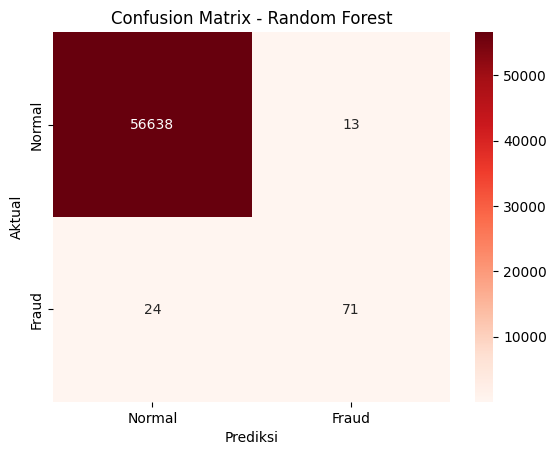

In [25]:
# Model terbaik berdasarkan PR-AUC (metrik paling jujur untuk data timpang)
best_name  = df_results['PR-AUC'].idxmax()
best_model = models[best_name]
pred_best  = best_model.predict(x_test_s)
proba_best = best_model.predict_proba(x_test_s)[:, 1]

print("Model terbaik:", best_name)
print(classification_report(y_test, pred_best, target_names=['Normal', 'Fraud'], digits=4))

sns.heatmap(confusion_matrix(y_test, pred_best), annot=True, fmt='d', cmap='Reds',
            xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title(f'Confusion Matrix - {best_name}')
plt.show()

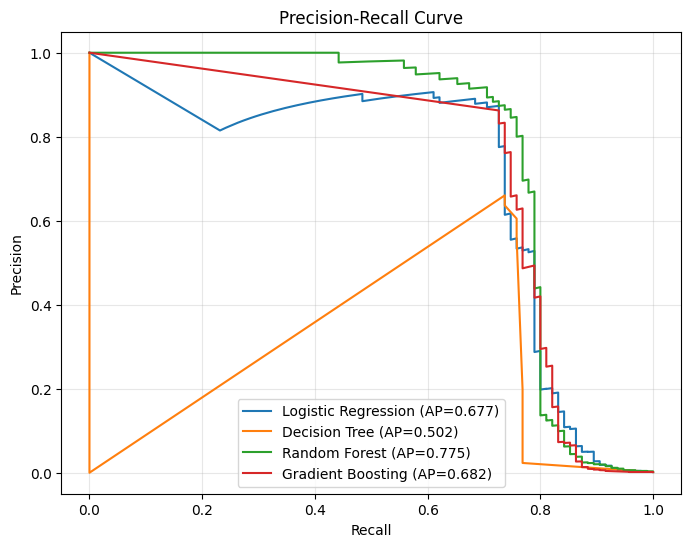

In [26]:
# Kurva Precision-Recall semua model
plt.figure(figsize=(8, 6))
for nama, m in models.items():
    p, r, _ = precision_recall_curve(y_test, m.predict_proba(x_test_s)[:, 1])
    plt.plot(r, p, label=f"{nama} (AP={df_results.loc[nama, 'PR-AUC']:.3f})")
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall Curve')
plt.legend(); plt.grid(alpha=0.3); plt.show()

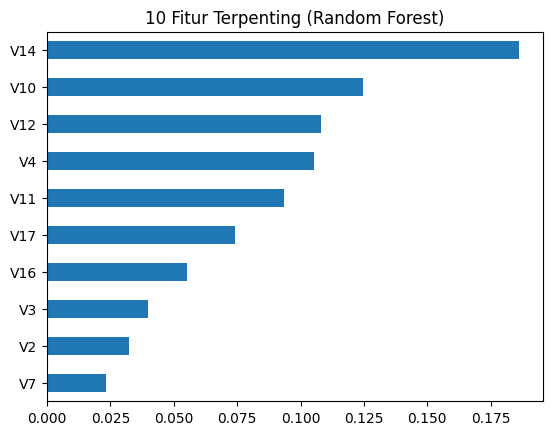

In [27]:
# Fitur terpenting (Random Forest)
imp = pd.Series(RF.feature_importances_, index=x_train_s.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('10 Fitur Terpenting (Random Forest)')
plt.show()

## 6. Deployment & Monitoring

### 6a. Deployment: simpan model dan buat fungsi prediksi
Yang disimpan bukan hanya model, tetapi juga **scaler/preprocessing** dan daftar kolom, karena data baru harus diproses persis seperti data latih.

In [28]:
import joblib
import pickle

paket = {
    'prep': prep,                       # scaler Amount & hour_of_day
    'model': best_model,                # model terbaik
    'nama_model': best_name,
    'kolom': x_train.columns.tolist(),  # urutan kolom input
    'threshold': 0.5,
}

joblib.dump(paket, 'fraud_model.joblib')

with open('fraud_model.pkl', 'wb') as file:
    pickle.dump(paket, file)

print("Model disimpan:", best_name)

Model disimpan: Random Forest


In [29]:
# Simulasi deployment: muat model, lalu buat fungsi prediksi untuk transaksi baru
paket = joblib.load('fraud_model.joblib')

def prediksi_transaksi(data_baru):
    """data_baru: dict / list of dict / DataFrame dengan kolom V1..V28, Amount, hour_of_day"""
    d = pd.DataFrame(data_baru) if not isinstance(data_baru, pd.DataFrame) else data_baru.copy()
    d = d[paket['kolom']]
    d_s = paket['prep'].transform(d)
    proba = paket['model'].predict_proba(d_s)[:, 1]
    return pd.DataFrame({
        'probabilitas_fraud': proba.round(4),
        'prediksi': np.where(proba >= paket['threshold'], 'FRAUD', 'Normal'),
    })

# Contoh: 1 transaksi fraud asli dan 2 transaksi normal dari data uji
contoh = pd.concat([x_test[y_test == 1].head(1), x_test[y_test == 0].head(2)])
print("Label asli:", y_test.loc[contoh.index].tolist())
prediksi_transaksi(contoh)

Label asli: [1, 0, 0]


,probabilitas_fraud,prediksi
0,0.0429,Normal
1,0.0618,Normal
2,0.0014,Normal


In [30]:
# Contoh format input JSON untuk API (satu transaksi)
import json
contoh_json = x_test[y_test == 1].iloc[0].to_dict()
print(json.dumps(contoh_json, indent=2)[:600], "...")

{
  "V1": -1.36029263351035,
  "V2": -0.45806896998712,
  "V3": -0.700403917726715,
  "V4": 2.73722917151503,
  "V5": -1.00510597388675,
  "V6": 2.89139936351597,
  "V7": 5.80253735302589,
  "V8": -1.93319735249124,
  "V9": -1.01771714252211,
  "V10": 1.987861862693,
  "V11": 0.504116141204789,
  "V12": -0.863430853145281,
  "V13": -0.184450076491427,
  "V14": -1.01691553500414,
  "V15": -1.55941019827384,
  "V16": 1.15431268558106,
  "V17": -2.04385766822656,
  "V18": -0.151698807119589,
  "V19": -0.94351353548825,
  "V20": -1.49340137472525,
  "V21": -0.936989532415364,
  "V22": -0.053811586 ...


In [31]:
# (Opsional) Membuat file API dengan FastAPI. Jalankan di terminal:  uvicorn app:app --reload
kode_api = '''
from fastapi import FastAPI
import joblib, pandas as pd, numpy as np

app = FastAPI(title="Fraud Detection API")
paket = joblib.load("fraud_model.joblib")

@app.post("/predict")
def predict(transaksi: dict):
    d = pd.DataFrame([transaksi])[paket["kolom"]]
    proba = float(paket["model"].predict_proba(paket["prep"].transform(d))[:, 1][0])
    return {"probabilitas_fraud": round(proba, 4),
            "prediksi": "FRAUD" if proba >= paket["threshold"] else "Normal"}
'''
with open('app.py', 'w') as f:
    f.write(kode_api.strip())
print("app.py dibuat (butuh: pip install fastapi uvicorn)")

app.py dibuat (butuh: pip install fastapi uvicorn)


### 6b. Monitoring
Setelah model dipakai, performanya bisa turun karena pola penipuan berubah (*drift*). Ada tiga hal yang dipantau:
1. **Logging prediksi** (siapa/kapan/berapa skor)
2. **Data drift**: apakah distribusi data baru berbeda dari data latih (pakai PSI)
3. **Performa model**: precision dan recall pada data yang labelnya sudah diketahui, dengan alarm jika turun di bawah batas

In [32]:
# 1. Logging prediksi ke file CSV
import os
from datetime import datetime

def log_prediksi(data_baru, file_log='prediction_log.csv'):
    hasil = prediksi_transaksi(data_baru)
    log = data_baru[['Amount', 'hour_of_day']].reset_index(drop=True).copy()
    log['probabilitas_fraud'] = hasil['probabilitas_fraud'].values
    log['prediksi'] = hasil['prediksi'].values
    log['waktu'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
    log.to_csv(file_log, mode='a', header=not os.path.exists(file_log), index=False)
    return hasil

if os.path.exists('prediction_log.csv'):
    os.remove('prediction_log.csv')
_ = log_prediksi(x_test.head(1000))
pd.read_csv('prediction_log.csv').head()

,Amount,hour_of_day,probabilitas_fraud,prediksi,waktu
0,1.00,17,0.0618,Normal,2026-10-16 06:23:10
1,9.72,19,0.0014,Normal,2026-10-16 06:23:10
2,1.50,2,0.0039,Normal,2026-10-16 06:23:10
3,3.57,19,0.0017,Normal,2026-10-16 06:23:10
4,105.90,21,0.0015,Normal,2026-10-16 06:23:10


In [33]:
# 2. Data drift dengan PSI (Population Stability Index)
#    PSI < 0.1 = stabil | 0.1-0.25 = perlu diperhatikan | > 0.25 = drift besar
def hitung_psi(awal, baru, bins=10):
    batas = np.unique(np.quantile(awal, np.linspace(0, 1, bins + 1)))
    batas[0], batas[-1] = -np.inf, np.inf
    p_awal = np.histogram(awal, bins=batas)[0] / len(awal)
    p_baru = np.histogram(baru, bins=batas)[0] / len(baru)
    p_awal, p_baru = np.clip(p_awal, 1e-6, None), np.clip(p_baru, 1e-6, None)
    return float(np.sum((p_baru - p_awal) * np.log(p_baru / p_awal)))

# Simulasi: batch "data baru" = 5000 data test, dan versi yang sengaja di-drift (Amount dikali 3)
batch_normal = x_test.sample(5000, random_state=1)
batch_drift  = batch_normal.copy()
batch_drift['Amount'] = batch_drift['Amount'] * 3

pantau = ['Amount', 'V14', 'V17', 'V12', 'V10']
tabel_psi = pd.DataFrame({
    'PSI batch normal': [hitung_psi(x_train[c], batch_normal[c]) for c in pantau],
    'PSI batch drift':  [hitung_psi(x_train[c], batch_drift[c])  for c in pantau],
}, index=pantau).round(4)
tabel_psi

,PSI batch normal,PSI batch drift
Amount,0.0013,0.4048
V14,0.0007,0.0007
V17,0.0011,0.0011
V12,0.0025,0.0025
V10,0.0017,0.0017


In [34]:
# 3. Monitoring performa + alarm
BATAS_RECALL, BATAS_PRECISION = 0.70, 0.70

def cek_performa(x_batch, y_batch):
    pred = (paket['model'].predict_proba(paket['prep'].transform(x_batch[paket['kolom']]))[:, 1] >= paket['threshold']).astype(int)
    p = precision_score(y_batch, pred, zero_division=0)
    r = recall_score(y_batch, pred, zero_division=0)
    status = 'OK' if (p >= BATAS_PRECISION and r >= BATAS_RECALL) else 'ALARM: model perlu dievaluasi/dilatih ulang'
    return {'fraud_di_batch': int(y_batch.sum()), 'precision': round(p, 3), 'recall': round(r, 3), 'status': status}

# Pantau per batch (data test dipecah acak jadi 5 batch)
idx = np.array_split(np.random.RandomState(1).permutation(len(x_test)), 5)
monitor = pd.DataFrame([cek_performa(x_test.iloc[i], y_test.iloc[i]) for i in idx])
monitor.index = [f'Batch {k+1}' for k in range(len(monitor))]
monitor

,fraud_di_batch,precision,recall,status
Batch 1,18,0.867,0.722,OK
Batch 2,11,0.692,0.818,ALARM: model perlu dievaluasi/dilatih ulang
Batch 3,22,0.778,0.636,ALARM: model perlu dievaluasi/dilatih ulang
Batch 4,24,0.857,0.750,OK
Batch 5,20,1.000,0.850,OK


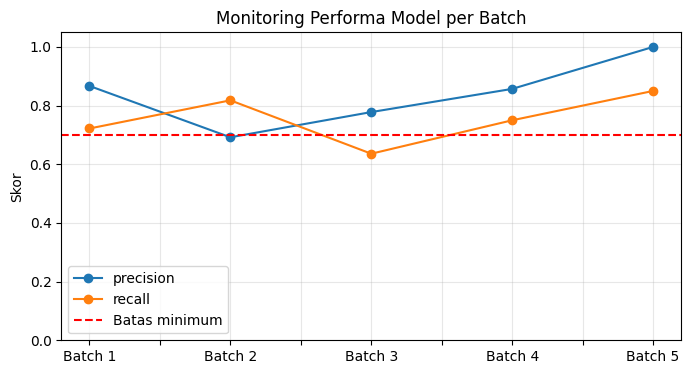

In [35]:
# Grafik monitoring: precision & recall per batch
monitor[['precision', 'recall']].plot(marker='o', figsize=(8, 4))
plt.axhline(BATAS_RECALL, color='red', linestyle='--', label='Batas minimum')
plt.ylim(0, 1.05); plt.title('Monitoring Performa Model per Batch')
plt.ylabel('Skor'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Catatan:** di dunia nyata label fraud baru diketahui belakangan (setelah ada laporan/chargeback), jadi monitoring performa dijalankan berkala (mis. mingguan), sedangkan monitoring drift (PSI) bisa dijalankan setiap hari karena tidak butuh label.